# 03 — Modeling

Model comparison, the class-imbalance study, tuning, calibration and the cost-based threshold. This notebook loads the result tables written by `main.py`, so the numbers are exactly what the pipeline produced.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
# run from repo root so `src` and configs resolve
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
pd.set_option("display.max_columns", 60)

## Model comparison

Four models on the same hold-out set. PR-AUC / KS / Brier matter more than accuracy at an 8% default rate.

In [2]:
cmp = pd.read_csv('reports/tables/model_comparison.csv')
cmp[['model','roc_auc','pr_auc','ks','gini','brier']].round(4)

,model,roc_auc,pr_auc,ks,gini,brier
0,logistic_regression,0.7718,0.2627,0.4063,0.5435,0.0669
1,random_forest,0.7616,0.2463,0.3916,0.5233,0.0682
2,xgboost,0.7860,0.2854,0.4363,0.5721,0.0657
3,lightgbm,0.7874,0.2888,0.4326,0.5747,0.0656


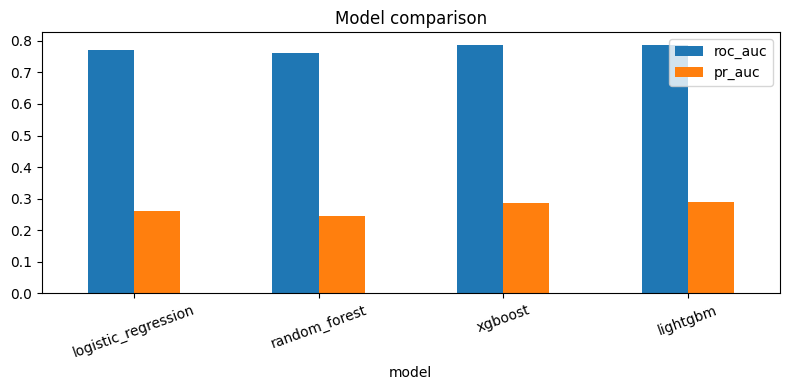

In [3]:
import matplotlib.pyplot as plt
ax = cmp.set_index('model')[['roc_auc','pr_auc']].plot.bar(rot=20, figsize=(8,4))
ax.set_title('Model comparison'); plt.tight_layout()

## Class imbalance

None / class-weight / SMOTE / threshold tuning.

In [4]:
imb = pd.read_csv('reports/tables/imbalance_comparison.csv')
imb.round(4)

,strategy,roc_auc,pr_auc,precision,recall,f1,ks
0,none,0.7788,0.2770,0.5524,0.0435,0.0807,0.4240
1,class_weight,0.7788,0.2735,0.2001,0.6365,0.3045,0.4223
2,smote,0.7605,0.2430,0.4850,0.0423,0.0778,0.3870
3,threshold@0.15,0.7788,0.2770,0.2636,0.4532,0.3333,NaN


Class weighting recovers recall at the same AUC; threshold tuning gives the best F1; SMOTE hurt AUC here.

## Tuning (Optuna)

In [5]:
best = json.load(open('reports/tables/optuna_best.json'))
for m, d in best.items():
    print(m, 'CV PR-AUC:', round(d['cv_pr_auc'],4), '| trials:', d['n_trials'])
best['lightgbm']['best_params']

xgboost CV PR-AUC: 0.2527 | trials: 15
lightgbm CV PR-AUC: 0.255 | trials: 15


{'n_estimators': 500,
 'learning_rate': 0.03729071850029894,
 'num_leaves': 41,
 'max_depth': 4,
 'min_child_samples': 144,
 'subsample': 0.8113765814398016,
 'colsample_bytree': 0.7281862707243373,
 'reg_alpha': 0.08409955473741981,
 'reg_lambda': 0.0889969628435704}

## Calibration

The final model was calibrated; Brier barely changed because LightGBM was already well-calibrated.

In [6]:
cal = json.load(open('reports/tables/calibration.json'))
print('Brier by variant:', {k: round(v,5) for k,v in cal['briers'].items()})
print('selected:', cal['selected'])
print('final hold-out metrics:', {k: round(v,4) for k,v in cal['final_val_metrics'].items() if k in ['roc_auc','pr_auc','ks','gini','brier']})

Brier by variant: {'uncalibrated': 0.06587, 'sigmoid': 0.06586, 'isotonic': 0.0659}
selected: sigmoid
final hold-out metrics: {'roc_auc': 0.7844, 'pr_auc': 0.2841, 'ks': 0.4288, 'gini': 0.5689, 'brier': 0.0659}


## Cost-based threshold

False negative : false positive assumed 5 : 1. The minimum expected cost picks the operating threshold and risk bands.

In [7]:
sweep = pd.read_csv('reports/tables/threshold_sweep.csv')
sweep.round(4)

,threshold,precision,recall,f1,approval_rate,rejection_rate,expected_cost_per_app
0,0.05,0.1410,0.8439,0.2417,0.5169,0.4831,0.4780
1,0.10,0.2058,0.6308,0.3104,0.7526,0.2474,0.3455
2,0.15,0.2643,0.4691,0.3381,0.8567,0.1433,0.3197
3,0.20,0.3177,0.3460,0.3312,0.9121,0.0879,0.3240
4,0.25,0.3654,0.2516,0.2980,0.9444,0.0556,0.3374
5,0.30,0.4090,0.1833,0.2531,0.9638,0.0362,0.3510
6,0.35,0.4425,0.1295,0.2004,0.9764,0.0236,0.3645
7,0.40,0.5017,0.0904,0.1532,0.9854,0.0146,0.3744
8,0.45,0.5247,0.0598,0.1074,0.9908,0.0092,0.3839
9,0.50,0.5976,0.0401,0.0751,0.9946,0.0054,0.3896


risk bands: {'approve_below': 0.15, 'reject_above': 0.2}


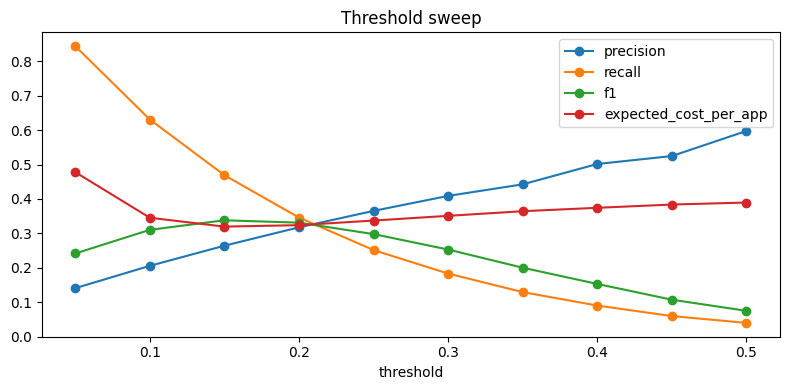

In [8]:
ax = sweep.set_index('threshold')[['precision','recall','f1','expected_cost_per_app']].plot(marker='o', figsize=(8,4))
ax.set_title('Threshold sweep'); plt.tight_layout()
print('risk bands:', json.load(open('reports/tables/risk_bands.json')))